<a href="https://colab.research.google.com/github/V-Kariuki/AI_for_Science_and_Engineering/blob/develop/Week4_Assignment_Exploring_the_Mathematics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Descriptive Statistics and Relationships Between Variables

This section explores four numerical variables relevant to maternal health risk prediction: Age, SystolicBP, DiastolicBP, and BS (blood sugar). We will calculate descriptive statistics to understand their distributions and variability, then examine the relationship between systolic and diastolic blood pressure using covariance, correlation, and a scatter plot.

In [2]:

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the maternal health dataset
csv_path = '/content/drive/MyDrive/Colab Notebooks/Maternal Health Risk Data Set.csv'
df = pd.read_csv(csv_path)

# Display dataset dimensions and a sample
print(f"Dataset contains {df.shape[0]} rows and {df.shape[1]} columns.")
display(df.head())


Mounted at /content/drive
Dataset contains 1014 rows and 7 columns.


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [4]:
#Inspect the dataset

# Display column names and data types
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame(name='Data Type'))

# Check for missing values
print("\nMissing values:")
display(df.isnull().sum().to_frame(name='Missing Values'))


Column names:
['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate', 'RiskLevel']

Data types:


,Data Type
Age,int64
SystolicBP,int64
DiastolicBP,int64
BS,float64
BodyTemp,float64
HeartRate,int64
RiskLevel,object



Missing values:


,Missing Values
Age,0
SystolicBP,0
DiastolicBP,0
BS,0
BodyTemp,0
HeartRate,0
RiskLevel,0


In [5]:
#Four numerical variables relevant to maternal health risk prediction

#Age: Age of the pregnant woman.

#SystolicBP: Systolic blood pressure.

#DiastolicBP: Diastolic blood pressure.

#BS: Blood sugar level.

# Select the four numerical variables
variables = ['Age', 'SystolicBP', 'DiastolicBP', 'BS']

# Convert selected columns to numeric if necessary
for col in variables:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Calculate descriptive statistics
statistics = pd.DataFrame({
    'Mean': df[variables].mean(),
    'Median': df[variables].median(),
    'Range': df[variables].max() - df[variables].min(),
    'Variance': df[variables].var(),
    'Standard Deviation': df[variables].std()
})

# Display results to two decimal places
display(statistics.round(2))


,Mean,Median,Range,Variance,Standard Deviation
Age,29.87,26.0,60.0,181.56,13.47
SystolicBP,113.20,120.0,90.0,338.70,18.40
DiastolicBP,76.46,80.0,51.0,192.82,13.89
BS,8.73,7.5,13.0,10.85,3.29


In [6]:

# Select the two variables and remove incomplete pairs
bp_data = df[['SystolicBP', 'DiastolicBP']].dropna()

# Calculate covariance and Pearson correlation
covariance = bp_data['SystolicBP'].cov(bp_data['DiastolicBP'])
correlation = bp_data['SystolicBP'].corr(bp_data['DiastolicBP'])

print(f"Covariance: {covariance:.2f}")
print(f"Pearson correlation: {correlation:.3f}")


Covariance: 201.12
Pearson correlation: 0.787


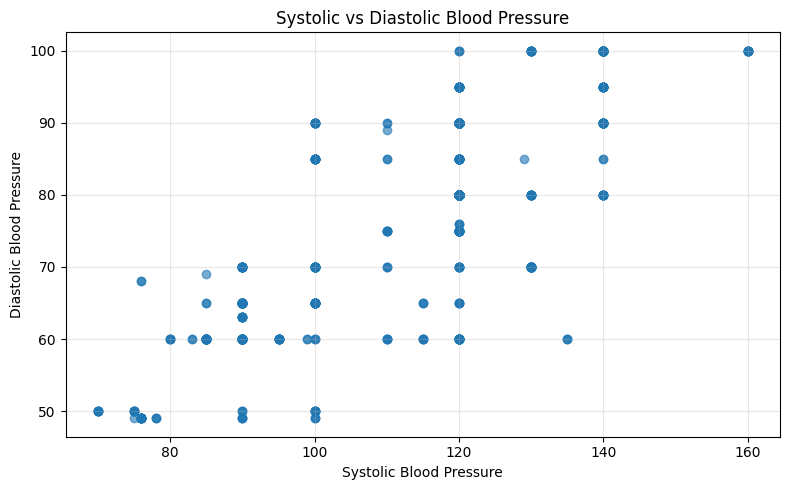

In [7]:
#A plot of the relationship

plt.figure(figsize=(8, 5))

plt.scatter(
    bp_data['SystolicBP'],
    bp_data['DiastolicBP'],
    alpha=0.6
)

plt.title('Systolic vs Diastolic Blood Pressure')
plt.xlabel('Systolic Blood Pressure')
plt.ylabel('Diastolic Blood Pressure')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Interpretation of the Results

The mean and median show the central values of each variable. Comparing them can help identify possible skewness in the distributions. The range shows the difference between the highest and lowest recorded values. Variance and standard deviation describe how much the observations vary; a larger standard deviation indicates greater spread in the original units.

Covariance indicates whether systolic and diastolic blood pressure tend to vary in the same or opposite directions. The correlation coefficient measures the direction and strength of their linear relationship. A positive correlation indicates that higher values of one variable tend to occur alongside higher values of the other, while a negative correlation indicates the opposite. A correlation close to zero indicates little linear relationship.

Correlation does not necessarily imply causation. Even if systolic and diastolic blood pressure are correlated, this does not prove that one causes changes in the other. Other physiological factors may influence both variables.

The actual values calculated above should be used to describe the strength and direction of the relationship observed in this dataset.

## Mathematical Representation: Input → Function/Model → Output

In this example, systolic blood pressure is the input, and the model predicts diastolic blood pressure as the output.

- **Input (x):** Systolic blood pressure (**SystolicBP**).
- **Function/Model (f):** A machine-learning regression model.
- **Output (y_pred):** Predicted diastolic blood pressure (`DiastolicBP`).

**Mathematical expression:**

`Input → Function/Model → Output`

`SystolicBP → f(x) → Predicted DiastolicBP`

In general, the relationship can be expressed as:

`y_pred = f(x)`

Here, `x` represents the input, `f` represents the model, and `y_pred` represents the predicted output. The model learns patterns from training data and uses them to make predictions.

This is a simple illustration of machine learning. In the main project, the intended prediction target is `RiskLevel` (low, mid, or high), using multiple maternal health features as inputs.